# Notebook 01 — Entender os dados

**O que buscamos aqui:** olhar os dados com calma, antes de qualquer modelo. Queremos responder quatro perguntas simples:

1. Os dados estão no formato esperado (unidade, eixos, gravidade)?
2. Cada base está estável, ou seja, tem uma só velocidade e nenhuma troca no meio?
3. O que muda no sinal entre as velocidades e entre normal e anomalia?
4. Em quais frequências a vibração aparece?

| Passo | O que fazemos | O que buscamos |
| --- | --- | --- |
| 1 | Configurar parâmetros | Um único lugar para ajustar caminhos e opções |
| 2 | (Opcional) Cortar um arquivo com várias velocidades | Uma base por velocidade e por condição |
| 3 | Carregar as bases | Cada arquivo vira uma base com nome, condição e velocidade |
| 4 | Conferir os dados | Unidade correta, sem valores faltando, gravidade no eixo esperado |
| 5 | Olhar 1 segundo de sinal | Enxergar a vibração e comparar as bases na mesma escala |
| 6 | Desvio padrão segundo a segundo | Confirmar que a base é estável |
| 7 | Features no tempo (desvio padrão, curtose e pico) | Ver quais bases já se separam só com o domínio do tempo |
| 8 | FFT com janela de Hanning | Ver em quais frequências a vibração aparece |
| 9 | Espectrograma | Ver como as frequências se comportam ao longo do tempo |

## Como usar

1. Coloque os CSVs numa pasta, **um arquivo por base**, com o nome `<condicao>_vel_<N>.csv`. Exemplos: `ventilador_normal_vel_1.csv` e `fita_1g_vel_2.csv`.
2. Cada CSV tem as colunas `x`, `y` e `z`, em m/s², amostradas a 1 kHz, com **uma condição e uma velocidade por arquivo**.
3. Ajuste o Passo 1 (principalmente o caminho da pasta) e rode as células de cima para baixo.

**Atenção:** se o seu arquivo tem várias velocidades na mesma gravação (como os dados antigos, de ~30 minutos), faça primeiro o Passo 2 para cortá-lo. Os demais passos assumem uma velocidade por base.

## Sobre os dados desta versão (dados novos)

Esta é a versão do Notebook 01 para os **dados novos** (pasta `NOVOS_DADOS`), que substituem os dados antigos como base principal:

* **Uma bateria de testes**, com o ventilador Mondial VSP30B e a **oscilação ligada**.
* **Quatro condições, nas três velocidades:** `ventilador_normal`, `fita_1g`, `papel` (folha que bate na hélice a cada volta) e `porca_frouxa`. São 12 bases, já gravadas separadas por velocidade.
* **Cada teste começou com o motor frio:** o grupo esperou cerca de 1 h entre um teste e outro. Por isso cada gravação pode carregar o **aquecimento do motor** ao longo dos ~10 minutos.
* **Os arquivos ficam em subpastas** (`NORMAL` e `ANOMALIA`). A leitura procura dentro delas (`BUSCAR_EM_SUBPASTAS = True`).
* Os notebooks da versão anterior (dados antigos) continuam na pasta `NOTEBOOKS_REPLICAVEIS`, como registro.

**Convenção das células:** cada função fica numa célula e a sua execução fica na célula seguinte.

## Passo 1 — Configuração

**O que buscamos:** concentrar tudo o que muda de um experimento para outro num só lugar. Para reaplicar o notebook em dados novos, basta mexer na célula de parâmetros.

In [1]:
from pathlib import Path
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
from scipy import signal
from scipy.stats import kurtosis
from IPython.display import display

plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.linestyle": "--", "grid.alpha": 0.4})

In [2]:
# ----------------------------------------------------------------------
# ONDE ESTÃO OS DADOS
# Pasta com UM CSV por base (pode estar em subpastas). Nome do arquivo = <condicao>_vel_<N>.csv
# ----------------------------------------------------------------------
PASTA_BASES = Path(r"C:\Users\santo\OneDrive\Área de Trabalho\TCC\DADOS\NOVOS_DADOS")
BUSCAR_EM_SUBPASTAS = True   # True = lê também os CSVs dentro das subpastas (NORMAL, ANOMALIA)

# ----------------------------------------------------------------------
# COMO OS DADOS FORAM COLETADOS
# ----------------------------------------------------------------------
TAXA_AMOSTRAGEM_HZ = 1000     # amostras por segundo (ESP32 + MPU6050)
EIXOS = ["x", "y", "z"]
UNIDADE = "m/s²"              # unidade dos valores nos CSVs

# ----------------------------------------------------------------------
# LIMPEZA DO COMEÇO E DO FIM DE CADA GRAVAÇÃO (Passo 4.1)
# ----------------------------------------------------------------------
DESCARTAR_INICIO_S = 5        # segundos descartados no começo de cada base (falhas de leitura ao ligar a gravação)
DESCARTAR_FIM_S = 5           # segundos descartados no fim de cada base (manuseio ao parar a gravação)
LIMITE_CURTOSE_SUSPEITA = 8   # janela com curtose acima disto, em algum eixo, é marcada como suspeita

# ----------------------------------------------------------------------
# PARÂMETROS DA ANÁLISE
# ----------------------------------------------------------------------
JANELA_S = 5                  # janela (s) das features e da FFT, sem sobreposição
F_MIN_HZ = 5                  # a FFT ignora frequências abaixo disto (deriva lenta do sensor)
F_MAX_HZ = 300                # limite superior dos gráficos de frequência
INICIO_TRECHO_S = None        # onde começa o trecho de 1 s dos gráficos (None = meio de cada base)
INICIO_FFT_S = 0              # segundo da base em que começa a janela usada nos gráficos de FFT
BASE_EXEMPLO = None           # base dos gráficos com uma única base (None = a primeira)
EIXO_ESPECTROGRAMA = "x"      # eixo usado no espectrograma

# ----------------------------------------------------------------------
# APARÊNCIA
# ----------------------------------------------------------------------
CORES_EIXOS = {"x": "red", "y": "green", "z": "blue"}
NOMES_EIXOS = {"x": "Eixo X (lateral)", "y": "Eixo Y (frontal)", "z": "Eixo Z (vertical)"}
CORES_VELOCIDADE = {1: "dodgerblue", 2: "crimson", 3: "limegreen"}
CONDICAO_NORMAL = "ventilador_normal"   # condição de referência, usada para montar os grupos do Passo 7.2
MARCADORES_CONDICAO = ["o", "^", "s", "D", "v"]

## Passo 2 (opcional) — Cortar um arquivo que tem várias velocidades

**O que buscamos:** transformar uma gravação longa, com as velocidades em sequência, em **uma base por velocidade**, cada uma num CSV com nome rotulado. Isto é feito **uma vez**. Depois, o notebook só lê a pasta de bases.

**Quando usar:** só se o seu arquivo tem mais de uma velocidade (caso dos dados antigos). **Os dados novos já vêm separados por velocidade: nesta versão, pule este passo.** As células de corte estão comentadas de propósito: se rodadas por engano, poderiam sobrescrever arquivos da pasta de bases.

**Como usar** (as duas células de execução abaixo estão comentadas):

1. Descomente a primeira célula (selecione todas as linhas e use `Ctrl + /`), ajuste o caminho e o prefixo do nome e rode. Ela mostra o desvio padrão segundo a segundo.
2. Nesse gráfico, os **degraus** são as trocas de velocidade. Anote o segundo de cada troca e deixe uma margem de segurança, para descartar o acionamento manual dos botões.
3. Descomente a segunda célula, preencha os cortes `{velocidade: (início_s, fim_s)}` e rode. Ela salva um CSV por velocidade em `PASTA_BASES`. A função **não sobrescreve** arquivos que já existem.
4. Comente as duas células de volta.

Cortes dos dados antigos, validados nos notebooks de ML (em segundos):

| Arquivo | Vel 1 | Vel 2 | Vel 3 |
| --- | --- | --- | --- |
| Normal | 20 a 620 | 660 a 1230 | 1270 a 1780 |
| Fita | 20 a 580 | 620 a 1170 | 1210 a 1800 |

In [3]:
def calcular_std_por_segundo(df):
    """Desvio padrão de cada eixo em cada segundo inteiro da base.

    O desvio padrão ignora a gravidade (valor constante) e mede só a intensidade
    da trepidação. O último segundo incompleto é descartado.
    """
    n_segundos = len(df) // TAXA_AMOSTRAGEM_HZ
    df = df[EIXOS].iloc[: n_segundos * TAXA_AMOSTRAGEM_HZ]
    segundo = np.arange(len(df)) // TAXA_AMOSTRAGEM_HZ
    return df.groupby(segundo).std()


def plotar_std_por_segundo(std_por_base):
    """Uma linha de gráfico por base, com o desvio padrão de X, Y e Z ao longo do tempo.

    std_por_base: dicionário {nome da base: saída de calcular_std_por_segundo}.
    """
    fig, axs = plt.subplots(len(std_por_base), 1, figsize=(15, 3.2 * len(std_por_base)), squeeze=False)
    for ax, (nome, std_seg) in zip(axs[:, 0], std_por_base.items()):
        for eixo in EIXOS:
            ax.plot(std_seg.index, std_seg[eixo], color=CORES_EIXOS[eixo], linewidth=1.2, label=NOMES_EIXOS[eixo])
        ax.set_title(nome, fontsize=12, fontweight="bold")
        ax.set_ylabel(f"Desvio padrão ({UNIDADE})")
        ax.xaxis.set_major_locator(MaxNLocator(nbins=15, integer=True))
        ax.legend(loc="lower right", bbox_to_anchor=(1.0, 1.0), ncol=3, fontsize=9, frameon=False)
    axs[-1, 0].set_xlabel("Tempo (s)")
    plt.tight_layout()
    plt.show()


def salvar_bases_recortadas(df_longo, cortes, prefixo_nome, pasta_saida, sobrescrever=False):
    """Corta o arquivo longo e salva um CSV por velocidade: <prefixo_nome>_vel_<N>.csv.

    cortes: dicionário {velocidade: (inicio_s, fim_s)}.
    """
    pasta_saida = Path(pasta_saida)
    pasta_saida.mkdir(parents=True, exist_ok=True)
    for velocidade, (inicio_s, fim_s) in cortes.items():
        destino = pasta_saida / f"{prefixo_nome}_vel_{velocidade}.csv"
        if destino.exists() and not sobrescrever:
            raise FileExistsError(f"{destino.name} já existe. Use sobrescrever=True se for de propósito.")
        trecho = df_longo[EIXOS].iloc[int(inicio_s * TAXA_AMOSTRAGEM_HZ): int(fim_s * TAXA_AMOSTRAGEM_HZ)]
        trecho.to_csv(destino, index=False)
        print(f"Salvo: {destino.name} ({len(trecho)} linhas = {len(trecho) / TAXA_AMOSTRAGEM_HZ:.0f} s)")

In [4]:
# ARQUIVO_LONGO = Path(r"C:\Users\santo\OneDrive\Área de Trabalho\TCC\DADOS\DADOS_NORMAIS_1KHZ\dados_valores_xyz_puro.csv")
# PREFIXO_NOME = "ventilador_normal"

# df_longo = pd.read_csv(ARQUIVO_LONGO)
# plotar_std_por_segundo({PREFIXO_NOME: calcular_std_por_segundo(df_longo)})

In [5]:
# ARQUIVO_LONGO = Path(r"C:\Users\santo\OneDrive\Área de Trabalho\TCC\DADOS\DADOS_FITA_1KHZ\dados_valores_xyz_puro_fita.csv")
# PREFIXO_NOME = "fita_1g"

# df_longo = pd.read_csv(ARQUIVO_LONGO)
# plotar_std_por_segundo({PREFIXO_NOME: calcular_std_por_segundo(df_longo)})

In [6]:
# CORTES = {
#      1: (20, 620),
#      2: (660, 1230),
#      3: (1270, 1780),
# }
# salvar_bases_recortadas(df_longo, CORTES, PREFIXO_NOME, PASTA_BASES, sobrescrever=True)

In [7]:
# CORTES = {
#     1: (20, 580),
#     2: (620, 1170),
#     3: (1210, 1800),
# }
# salvar_bases_recortadas(df_longo, CORTES, PREFIXO_NOME, PASTA_BASES)

## Passo 3 — Carregar as bases

**O que buscamos:** ler todos os CSVs da pasta e guardar, para cada base, o **nome**, a **condição** (ex.: `fita_1g`) e a **velocidade** (ex.: `2`), que vêm do nome do arquivo. O nome do arquivo é o gabarito, então ele precisa seguir o padrão `<condicao>_vel_<N>`.

O resultado são dois objetos:

* `bases`: dicionário `{nome da base: tabela com x, y e z}`.
* `catalogo`: tabela-resumo com uma linha por base (condição, velocidade, número de linhas e duração).

Também definimos aqui a função que monta os gráficos em **grade**, com uma linha por condição e uma coluna por velocidade. Assim, normal e anomalia ficam lado a lado.

In [8]:
PADRAO_NOME = re.compile(r"^(?P<condicao>.+)_vel_(?P<velocidade>\d+)$")


def ler_rotulo_do_nome(nome_base):
    """Separa o nome 'fita_1g_vel_2' em condição ('fita_1g') e velocidade (2)."""
    encontrado = PADRAO_NOME.match(nome_base)
    if encontrado is None:
        raise ValueError(
            f"Nome fora do padrão: '{nome_base}'. Use <condicao>_vel_<N>, por exemplo 'fita_1g_vel_2'."
        )
    return encontrado["condicao"], int(encontrado["velocidade"])


def carregar_base(caminho):
    """Lê um CSV e devolve só as colunas x, y e z como números decimais."""
    df = pd.read_csv(caminho)
    faltando = [eixo for eixo in EIXOS if eixo not in df.columns]
    if faltando:
        raise ValueError(f"{Path(caminho).name}: faltam as colunas {faltando}. Colunas encontradas: {list(df.columns)}")
    return df[EIXOS].astype(float)


def carregar_todas_as_bases(pasta):
    """Lê todos os CSVs da pasta. Devolve (bases, catalogo), ordenados por condição e velocidade."""
    arquivos = sorted(Path(pasta).rglob("*.csv") if BUSCAR_EM_SUBPASTAS else Path(pasta).glob("*.csv"))
    if not arquivos:
        raise FileNotFoundError(
            f"Nenhum CSV em '{pasta}'. Confira PASTA_BASES ou, se o arquivo tem várias velocidades, faça o Passo 2."
        )
    bases, linhas = {}, []
    for arquivo in arquivos:
        nome = arquivo.stem
        condicao, velocidade = ler_rotulo_do_nome(nome)
        bases[nome] = carregar_base(arquivo)
        linhas.append({
            "base": nome,
            "condicao": condicao,
            "velocidade": velocidade,
            "linhas": len(bases[nome]),
            "duracao_s": len(bases[nome]) / TAXA_AMOSTRAGEM_HZ,
        })
    catalogo = pd.DataFrame(linhas).sort_values(["condicao", "velocidade"]).set_index("base")
    bases = {nome: bases[nome] for nome in catalogo.index}
    return bases, catalogo


def criar_grade(catalogo, largura=6, altura=3.2, sharex=True, sharey=True, rotulo_x=None, rotulo_y=None):
    """Cria uma grade de gráficos: uma linha por condição e uma coluna por velocidade.

    rotulo_x vai embaixo de cada coluna e rotulo_y à esquerda de cada linha.
    Devolve (figura, eixos, celulas), onde celulas é a lista [(eixo do gráfico, nome da base), ...]
    só com as combinações que existem. As combinações sem base ficam ocultas.
    """
    condicoes = sorted(catalogo["condicao"].unique())
    velocidades = sorted(catalogo["velocidade"].unique())
    nome_por_celula = {(linha.condicao, linha.velocidade): nome for nome, linha in catalogo.iterrows()}

    fig, axs = plt.subplots(
        len(condicoes), len(velocidades),
        figsize=(largura * len(velocidades), altura * len(condicoes)),
        sharex=sharex, sharey=sharey, squeeze=False,
    )
    celulas = []
    for i, condicao in enumerate(condicoes):
        for j, velocidade in enumerate(velocidades):
            nome = nome_por_celula.get((condicao, velocidade))
            if nome is None:
                axs[i, j].set_visible(False)
                continue
            axs[i, j].set_title(f"{condicao} — Vel {velocidade}", fontsize=11, fontweight="bold")
            celulas.append((axs[i, j], nome))
            # rótulo do eixo x só na última célula visível de cada coluna
            ultima_linha = max(k for k, c in enumerate(condicoes) if (c, velocidade) in nome_por_celula)
            if rotulo_x and i == ultima_linha:
                axs[i, j].set_xlabel(rotulo_x)
            if rotulo_y and j == 0:
                axs[i, j].set_ylabel(rotulo_y)
    return fig, axs, celulas

In [9]:
bases, catalogo = carregar_todas_as_bases(PASTA_BASES)
display(catalogo)

,condicao,velocidade,linhas,duracao_s
base,,,,
fita_1g_vel_1,fita_1g,1,629500,629.500
fita_1g_vel_2,fita_1g,2,657000,657.000
fita_1g_vel_3,fita_1g,3,643500,643.500
papel_vel_1,papel,1,639000,639.000
papel_vel_2,papel,2,643000,643.000
papel_vel_3,papel,3,652500,652.500
porca_frouxa_vel_1,porca_frouxa,1,648000,648.000
porca_frouxa_vel_2,porca_frouxa,2,648492,648.492
porca_frouxa_vel_3,porca_frouxa,3,650500,650.500


In [10]:
CONDICOES_USADAS = None   # exemplo: ["ventilador_normal"]. None = usa todas
if CONDICOES_USADAS is not None:
    catalogo = catalogo[catalogo["condicao"].isin(CONDICOES_USADAS)]
    bases = {nome: bases[nome] for nome in catalogo.index}

## Passo 4 — Conferir os dados

**O que buscamos:** garantir que os dados fazem sentido antes de analisar. Olhamos três coisas:

* **Valores faltando** (`nan`): devem ser zero.
* **Unidade:** o eixo Z mede a gravidade. Em m/s² ele fica perto de 9,8 (nos dados antigos, ~10,8, por causa do offset do sensor). Se ficasse perto de 1, os dados estariam em g.
* **Orientação do sensor:** os eixos X e Y devem ficar perto de 0, pois são perpendiculares à gravidade. Se o Z não for o eixo da gravidade, a montagem do sensor mudou e os nomes "lateral, frontal e vertical" deixam de valer.

In [11]:
def resumir_bases(bases):
    """Tabela com valores faltando, média e desvio padrão de cada eixo, por base."""
    linhas = []
    for nome, df in bases.items():
        linha = {"base": nome, "nan": int(df.isna().sum().sum())}
        for eixo in EIXOS:
            linha[f"media_{eixo}"] = df[eixo].mean()
        for eixo in EIXOS:
            linha[f"std_{eixo}"] = df[eixo].std()
        linhas.append(linha)
    return pd.DataFrame(linhas).set_index("base")

In [12]:
resumo = resumir_bases(bases)
display(resumo.round(3))

,nan,media_x,media_y,media_z,std_x,std_y,std_z
base,,,,,,,
fita_1g_vel_1,0,-0.865,-0.476,10.646,1.023,0.954,0.358
fita_1g_vel_2,0,-0.783,-0.392,10.651,8.921,7.140,5.398
fita_1g_vel_3,0,-0.673,-0.379,10.666,4.405,5.191,3.588
papel_vel_1,0,-0.694,-0.345,10.697,1.411,2.204,1.862
papel_vel_2,0,-0.614,-0.323,10.688,2.570,2.144,1.759
papel_vel_3,0,-0.599,-0.262,10.693,2.189,2.657,2.456
porca_frouxa_vel_1,0,-0.438,-0.337,10.750,0.769,0.867,0.573
porca_frouxa_vel_2,0,-0.323,-0.316,10.754,2.000,1.360,0.609
porca_frouxa_vel_3,0,-0.246,-0.284,10.760,1.087,0.926,0.770


### Conclusões do Passo 4 (nesta execução, dados novos)

* **12 bases, de 629 a 657 s cada** (antes do corte do Passo 4.2). Nenhum valor faltando.
* **Unidade e orientação iguais às dos dados antigos:** o eixo Z fica em ~10,6–10,8 m/s² (gravidade com o offset do sensor) e X e Y perto de zero.
* **Detalhe a observar:** a média de X muda um pouco entre as condições (de −0,87 na fita V1 a −0,25 na porca V3), e dentro de cada condição cresce da Vel 1 para a Vel 3. Uma diferença de ~0,4 m/s² na média corresponde a uma inclinação de cerca de 2° no sensor. Isso **não afeta as features**, que são calculadas depois de remover a média, mas indica que a posição do ventilador ou do sensor pode ter mudado um pouco entre os testes (por exemplo, ao instalar cada falha).
* **A curtose média de algumas bases está muito alta** (eixo Y do normal V2 ≈ 20). O Passo 4.1 mostra a causa.

### 4.1 — Picos isolados no começo e no fim das gravações

**O que buscamos:** encontrar trechos com **falhas de leitura do sensor** ou **manuseio**, que não são vibração do ventilador. Uma falha típica é **uma única amostra absurda**: por exemplo, 87 m/s² no meio de valores perto de 0, ou um 0 no meio de valores perto de 10,7. Ela é rápida demais para ser vibração real.

**Como encontramos:** pela **curtose** de cada janela de `JANELA_S` segundos. A curtose mede o quanto um sinal tem picos raros e fortes. Uma vibração comum fica entre −1 e 3; **uma única amostra absurda faz a curtose da janela ir a centenas ou milhares**. A tabela lista as janelas com curtose acima de `LIMITE_CURTOSE_SUSPEITA` em algum eixo, com a **posição da janela** na gravação (janela 0 = primeiros 5 s).

**O que procurar:** se as janelas suspeitas se concentram **no começo ou no fim** das gravações, a causa é ligar e desligar a gravação, e basta descartar esses trechos. Se aparecerem **no meio**, é preciso olhar caso a caso.

In [13]:
def encontrar_janelas_suspeitas(bases, janela_s=JANELA_S, limite=LIMITE_CURTOSE_SUSPEITA):
    """Janelas (sem sobreposição) com curtose acima do limite em algum eixo, com a posição na gravação."""
    tamanho = int(janela_s * TAXA_AMOSTRAGEM_HZ)
    linhas = []
    for nome, df in bases.items():
        n_janelas = len(df) // tamanho
        dados = df[EIXOS].to_numpy()[: n_janelas * tamanho].reshape(n_janelas, tamanho, len(EIXOS))
        curtose = kurtosis(dados - dados.mean(axis=1, keepdims=True), axis=1, fisher=True)
        for janela in np.where((curtose > limite).any(axis=1))[0]:
            linha = {"base": nome, "janela": int(janela), "de": n_janelas - 1,
                     "trecho (s)": f"{janela * janela_s}–{(janela + 1) * janela_s}"}
            for k, eixo in enumerate(EIXOS):
                linha[f"curtose_{eixo}"] = round(float(curtose[janela, k]), 1)
            linhas.append(linha)
    return pd.DataFrame(linhas)

In [14]:
janelas_suspeitas = encontrar_janelas_suspeitas(bases)
if janelas_suspeitas.empty:
    print("Nenhuma janela suspeita.")
else:
    display(janelas_suspeitas)
    no_comeco = (janelas_suspeitas["janela"] == 0).sum()
    no_fim = (janelas_suspeitas["janela"] == janelas_suspeitas["de"]).sum()
    print(f"{len(janelas_suspeitas)} janelas suspeitas: {no_comeco} na primeira janela, {no_fim} na última, "
          f"{len(janelas_suspeitas) - no_comeco - no_fim} no meio.")

,base,janela,de,trecho (s),curtose_x,curtose_y,curtose_z
0,fita_1g_vel_1,0,124,0–5,10.5,3.7,1458.9
1,fita_1g_vel_2,0,130,0–5,1.4,1.0,1348.6
2,papel_vel_2,0,127,0–5,5.4,3.2,9.5
3,papel_vel_3,0,129,0–5,13.6,9.1,14.8
4,porca_frouxa_vel_1,0,128,0–5,3.7,2.5,15.9
5,porca_frouxa_vel_3,129,129,645–650,3.1,30.6,10.1
6,ventilador_normal_vel_1,0,128,0–5,25.2,8.0,1800.3
7,ventilador_normal_vel_2,0,130,0–5,18.3,2628.6,197.6
8,ventilador_normal_vel_3,0,125,0–5,26.3,-0.3,3.4


9 janelas suspeitas: 8 na primeira janela, 1 na última, 0 no meio.


### 4.2 — Descartar o começo e o fim de cada base

**O que fazemos:** cortamos `DESCARTAR_INICIO_S` segundos do começo e `DESCARTAR_FIM_S` do fim de **todas** as bases, mesmo das que não tiveram janela suspeita. Assim todas passam pelo mesmo tratamento e nenhuma condição fica com vantagem. **Todos os passos seguintes usam as bases já aparadas.**

**Por que só 5 s:** as falhas encontradas ficam todas dentro dos primeiros 3 s ou do último segundo. 5 s é a menor margem que cobre todas e é igual a uma janela. Se a tabela de conferência abaixo ainda mostrar janelas suspeitas, aumente os valores no Passo 1.

> **Os notebooks seguintes (02 em diante) aplicam o mesmo corte**, com os mesmos parâmetros, para que as features sejam calculadas exatamente sobre os mesmos trechos.

In [15]:
def aparar_bases(bases, catalogo, inicio_s=DESCARTAR_INICIO_S, fim_s=DESCARTAR_FIM_S):
    """Descarta inicio_s segundos do começo e fim_s do fim de cada base. Devolve (bases, catalogo) atualizados."""
    inicio, fim = int(inicio_s * TAXA_AMOSTRAGEM_HZ), int(fim_s * TAXA_AMOSTRAGEM_HZ)
    aparadas = {nome: df.iloc[inicio: len(df) - fim].reset_index(drop=True) for nome, df in bases.items()}
    catalogo = catalogo.copy()
    catalogo["linhas"] = [len(aparadas[nome]) for nome in catalogo.index]
    catalogo["duracao_s"] = catalogo["linhas"] / TAXA_AMOSTRAGEM_HZ
    return aparadas, catalogo

In [16]:
bases, catalogo = aparar_bases(bases, catalogo)
print(f"Descartados {DESCARTAR_INICIO_S} s do começo e {DESCARTAR_FIM_S} s do fim de cada base.")
display(catalogo)

conferencia = encontrar_janelas_suspeitas(bases)
print("Janelas suspeitas depois do corte:", "nenhuma" if conferencia.empty else "")
if not conferencia.empty:
    display(conferencia)

Descartados 5 s do começo e 5 s do fim de cada base.


,condicao,velocidade,linhas,duracao_s
base,,,,
fita_1g_vel_1,fita_1g,1,619500,619.500
fita_1g_vel_2,fita_1g,2,647000,647.000
fita_1g_vel_3,fita_1g,3,633500,633.500
papel_vel_1,papel,1,629000,629.000
papel_vel_2,papel,2,633000,633.000
papel_vel_3,papel,3,642500,642.500
porca_frouxa_vel_1,porca_frouxa,1,638000,638.000
porca_frouxa_vel_2,porca_frouxa,2,638492,638.492
porca_frouxa_vel_3,porca_frouxa,3,640500,640.500


Janelas suspeitas depois do corte: nenhuma


### Conclusões dos Passos 4.1 e 4.2 (nesta execução)

* **9 janelas suspeitas: 8 são a primeira janela (0 a 5 s) da gravação e 1 é a última** (porca frouxa V3, 645–650 s). **Nenhuma no meio.**
* **As piores são falhas de leitura do sensor, uma única amostra absurda:** curtose de 2.629 no eixo Y do normal V2 (um valor de 87 m/s² no meio de valores perto de 0), e de 1.300 a 1.800 no eixo Z do normal V1, da fita V1 e da fita V2 (valores de ~40 m/s² ou de 0 no meio de valores perto de 10,7). Acontecem nos primeiros 1 a 3 segundos, quando a gravação começa.
* **Depois de descartar 5 s do começo e 5 s do fim, não sobra nenhuma janela suspeita.** As bases ficam com 619 a 647 s, ou 123 a 129 janelas de 5 s.
* **Por que isso importa:** uma única amostra de 87 m/s² muda o pico e a curtose daquela janela e pode criar uma "janela atípica" falsa nos notebooks seguintes. Nos dados antigos isso não aparecia porque os cortes tinham margem de 20 s no começo de cada velocidade.

## Passo 5 — Olhar 1 segundo de sinal

**O que buscamos:** enxergar a vibração em si. Mostramos 1 segundo (1000 amostras) de cada base, nos três eixos, com **a mesma escala vertical** em todos os gráficos, para comparar a espessura da faixa de vibração entre as bases.

* **5.1 — Sinal bruto:** o Z fica deslocado pela gravidade, o que confirma a orientação do sensor.
* **5.2 — Sem o componente DC:** subtraímos a média de cada eixo, o que remove a gravidade e centraliza tudo em zero. Fica só a vibração, e é assim que ela entra nas features e na FFT.

In [17]:
def escolher_inicio_do_trecho(df, duracao_s, inicio_s=None):
    """Segundo em que o trecho começa. Se inicio_s for None, usa o meio da base."""
    if inicio_s is not None:
        return inicio_s
    duracao_total_s = len(df) / TAXA_AMOSTRAGEM_HZ
    return max(0, int((duracao_total_s - duracao_s) / 2))


def extrair_trecho(df, inicio_s, duracao_s, remover_dc):
    """Recorta um trecho da base. Com remover_dc=True, subtrai a média de cada eixo."""
    inicio = int(inicio_s * TAXA_AMOSTRAGEM_HZ)
    fim = inicio + int(duracao_s * TAXA_AMOSTRAGEM_HZ)
    trecho = df[EIXOS].iloc[inicio:fim]
    if remover_dc:
        trecho = trecho - trecho.mean()
    return trecho.reset_index(drop=True)


def plotar_trechos(bases, catalogo, duracao_s=1, inicio_s=None, remover_dc=False):
    """Grade (condição x velocidade) com um trecho de sinal de cada base, na mesma escala."""
    fig, axs, celulas = criar_grade(
        catalogo, sharex=True, sharey=True, rotulo_x="Tempo (s)", rotulo_y=f"Aceleração ({UNIDADE})"
    )
    for ax, nome in celulas:
        inicio = escolher_inicio_do_trecho(bases[nome], duracao_s, inicio_s)
        trecho = extrair_trecho(bases[nome], inicio, duracao_s, remover_dc)
        tempo = np.arange(len(trecho)) / TAXA_AMOSTRAGEM_HZ
        for eixo in EIXOS:
            ax.plot(tempo, trecho[eixo], color=CORES_EIXOS[eixo], linewidth=1, alpha=0.85, label=NOMES_EIXOS[eixo])
    axs[0, 0].legend(loc="upper right", fontsize=8)
    texto_dc = "sem o componente DC" if remover_dc else "sinal bruto (com gravidade)"
    fig.suptitle(f"{duracao_s} s de sinal — {texto_dc}", fontsize=14, fontweight="bold")
    plt.tight_layout()
    plt.show()

### 5.1 — Sinal bruto (com gravidade)

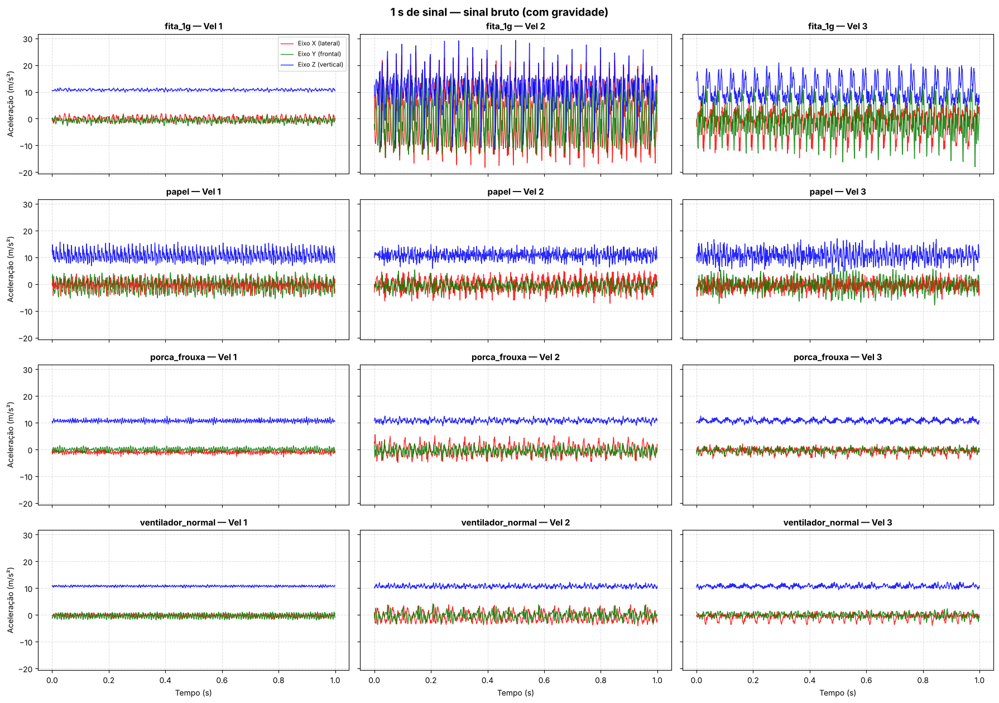

In [18]:
plotar_trechos(bases, catalogo, duracao_s=1, inicio_s=INICIO_TRECHO_S, remover_dc=False)

### 5.2 — Sem o componente DC (só a vibração)

Compare normal e anomalia na mesma velocidade (mesma coluna), e depois as velocidades entre si.

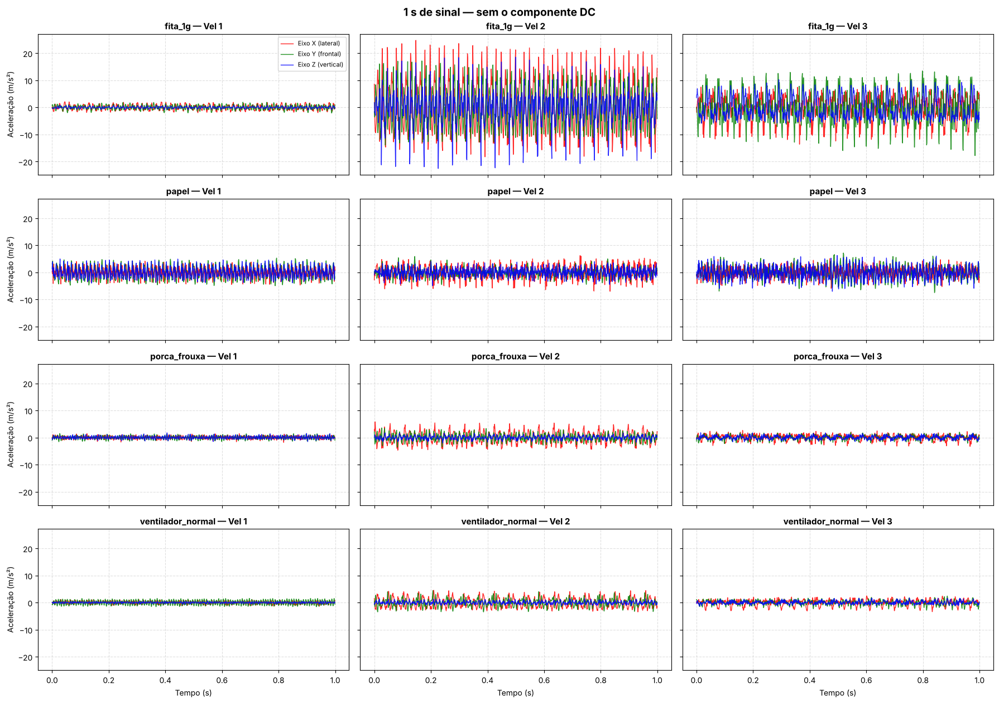

In [19]:
plotar_trechos(bases, catalogo, duracao_s=1, inicio_s=INICIO_TRECHO_S, remover_dc=True)

### Conclusões do Passo 5 (nesta execução)

**No sinal sem DC (5.2), dá para ver três níveis de vibração:**

* **A fita é a mais forte, nas Vel 2 e 3:** picos de ±20 m/s² na Vel 2 e ±10–15 na Vel 3, com impactos regulares bem visíveis. **Na Vel 1 ela quase não se distingue do normal** a olho.
* **O papel vibra mais que o normal nas três velocidades** (±4–5 m/s²), com um sinal mais "denso", de frequência alta, coerente com o papel batendo na hélice a cada volta.
* **A porca frouxa é parecida com o normal** em todas as velocidades. Na Vel 2 as duas são praticamente iguais a olho. É a falha sutil.

## Passo 6 — Desvio padrão segundo a segundo (a base é estável?)

**O que buscamos:** confirmar que cada base tem **um único regime**, ou seja, que o **patamar** do desvio padrão não muda ao longo da base. Calculamos o desvio padrão de cada segundo (as funções de cálculo e de gráfico foram definidas no Passo 2).

* **Oscilação regular em torno de um patamar:** nos dados antigos, todas as bases mostram uma oscilação periódica de alguns segundos. Ela **não** indica problema. O que importa é o nível médio.
* **Degrau (mudança de patamar) no meio da base:** houve troca de velocidade ou mudança no ensaio. A base precisa ser cortada de novo (Passo 2).
* **Picos isolados:** perturbação no teste, como um toque no ventilador.

A tabela de apoio mostra a **mudança do desvio padrão médio entre o início e o fim** da base (último terço contra o primeiro terço, em %). Como a oscilação regular se compensa nas médias, um valor alto indica mudança de patamar ou deriva. Não há um limite fixo: compare uma base com as outras e olhe sempre o gráfico.

In [20]:
def resumir_estabilidade(std_por_base):
    """Desvio padrão médio de cada base e a mudança (em %) do primeiro para o último terço da base.

    Um valor alto de mudança indica degrau ou deriva. A oscilação regular se compensa nas médias.
    """
    linhas = []
    for nome, std_seg in std_por_base.items():
        terco = len(std_seg) // 3
        linha = {"base": nome}
        for eixo in EIXOS:
            linha[f"std_medio_{eixo}"] = std_seg[eixo].mean()
        for eixo in EIXOS:
            inicio = std_seg[eixo].iloc[:terco].mean()
            fim = std_seg[eixo].iloc[-terco:].mean()
            linha[f"mudanca_%_{eixo}"] = 100 * (fim - inicio) / inicio
        linhas.append(linha)
    return pd.DataFrame(linhas).set_index("base")

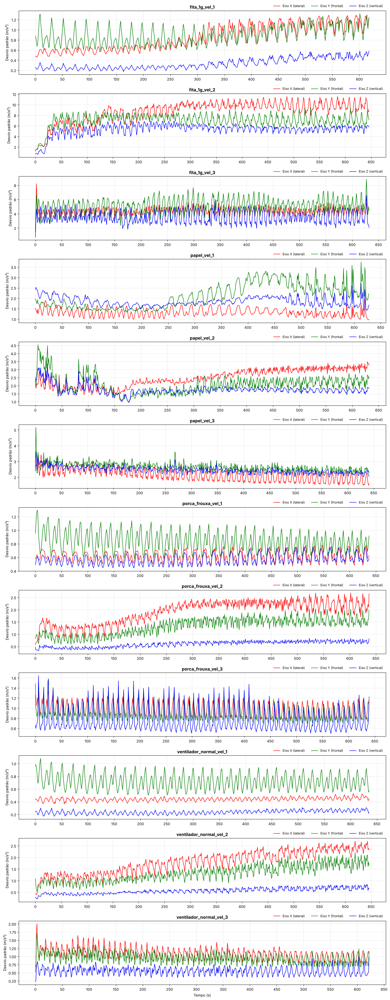

,std_medio_x,std_medio_y,std_medio_z,mudanca_%_x,mudanca_%_y,mudanca_%_z
base,,,,,,
fita_1g_vel_1,0.842,0.899,0.331,86.762,24.978,87.138
fita_1g_vel_2,8.700,7.065,5.320,50.073,3.366,15.454
fita_1g_vel_3,4.362,5.101,3.497,4.283,12.253,-1.268
papel_vel_1,1.317,2.106,1.849,-4.294,69.757,-0.729
papel_vel_2,2.475,2.061,1.738,59.307,5.336,-5.299
papel_vel_3,2.120,2.643,2.455,-22.655,-13.062,-12.994
porca_frouxa_vel_1,0.618,0.830,0.568,3.127,-8.648,11.783
porca_frouxa_vel_2,1.907,1.311,0.599,66.682,68.822,51.193
porca_frouxa_vel_3,0.981,0.897,0.739,-8.818,-8.123,-7.569


In [21]:
std_por_base = {nome: calcular_std_por_segundo(df) for nome, df in bases.items()}
plotar_std_por_segundo(std_por_base)
display(resumir_estabilidade(std_por_base).round(3))

### Conclusões do Passo 6 (nesta execução)

**1. O ciclo da oscilação aparece em todas as bases** (o "serrilhado" regular), como nos dados antigos. Esperado, já que a oscilação ficou ligada.

**2. Não há degraus de troca de velocidade:** cada base tem uma velocidade só.

**3. Mas várias bases mudam de patamar aos poucos, e o padrão depende da velocidade:**

| Velocidade | O que acontece | Exemplos (mudança do 1º para o último terço) |
| --- | --- | --- |
| **Vel 2** | **A vibração cresce ao longo da gravação, em todas as condições** | normal: X +84%, Y +74%; porca: X +67%, Y +69%; papel: X +59%; fita: X +50% |
| **Vel 1** | Cresce em algumas bases | fita: X e Z +87%; papel: Y +70%; normal e porca: estáveis (< 16%) |
| **Vel 3** | Estável ou caindo um pouco | normal −15%, papel −23%, porca −9%, fita +4% |

**Interpretação (hipótese):** como cada teste começou com o motor frio, a **rotação sobe enquanto o motor aquece** nas Vel 1 e 2 (o espectrograma do Passo 9 mostra isso). Na Vel 2 a rotação se aproxima de uma faixa em que a estrutura vibra mais, e a intensidade cresce junto. Na Vel 3 a rotação já começa estável.

**4. Dois começos diferentes dos demais:**
* **fita V2:** a vibração começa baixa (~1–2 m/s²) e só sobe para o patamar de ~6–8 m/s² depois de ~30 s.
* **papel V2:** os primeiros ~150 s são irregulares, com saltos, e depois a vibração se acomoda. Provavelmente o papel se ajeitando contra a hélice.

**O que isso significa para os próximos notebooks:**
* **O "normal" muda dentro da própria gravação** (normal V2: +84% em X). O controle do Notebook 02 (1ª metade × 2ª metade) vai medir isso, e um modelo precisa aprender que o normal frio e o normal quente são ambos normais.
* **As condições foram gravadas todas a partir do motor frio**, então o aquecimento afeta todas igualmente e a comparação entre elas continua justa.

## Passo 7 — Features no domínio do tempo (desvio padrão, curtose e pico)

**O que buscamos:** resumir cada janela de `JANELA_S` segundos (sem sobreposição) em poucos números e ver **quais bases já se separam** só com isso. São as mesmas 9 features de tempo do dataset do grupo, calculadas depois de remover o componente DC:

* **Desvio padrão (`std`):** intensidade da vibração.
* **Curtose (`kurt`, definição de Fisher):** perto de 0 quando o sinal se parece com uma distribuição normal. Valores positivos indicam picos raros e fortes, como impactos.
* **Pico (`pico`):** maior valor absoluto da janela, ou seja, a amplitude máxima.

A última janela incompleta de cada base é descartada.

* **7.1 — Boxplots:** uma caixa por base. Caixas que não se sobrepõem indicam que a feature separa aquelas bases.
* **7.2 — Dispersão 3D do desvio padrão:** cada ponto é uma janela (cor = velocidade, símbolo = condição). Grupos separados no espaço indicam bases distinguíveis.

In [22]:
def calcular_features_tempo(df, janela_s=JANELA_S):
    """Calcula std, curtose e pico de cada eixo, em cada janela sem sobreposição.

    Devolve uma tabela com uma linha por janela e as colunas std_x, kurt_x, pico_x, std_y, ...
    """
    tamanho = int(janela_s * TAXA_AMOSTRAGEM_HZ)
    n_janelas = len(df) // tamanho
    dados = df[EIXOS].to_numpy()[: n_janelas * tamanho]
    janelas = dados.reshape(n_janelas, tamanho, len(EIXOS))        # (janela, amostra, eixo)
    janelas = janelas - janelas.mean(axis=1, keepdims=True)         # remove o componente DC de cada janela

    std = janelas.std(axis=1, ddof=1)
    curtose = kurtosis(janelas, axis=1, fisher=True)
    pico = np.abs(janelas).max(axis=1)

    colunas = {}
    for k, eixo in enumerate(EIXOS):
        colunas[f"std_{eixo}"] = std[:, k]
        colunas[f"kurt_{eixo}"] = curtose[:, k]
        colunas[f"pico_{eixo}"] = pico[:, k]
    return pd.DataFrame(colunas)


def calcular_features_de_todas_as_bases(bases, catalogo, janela_s=JANELA_S):
    """Junta as features de todas as bases numa só tabela, com as colunas base, condicao e velocidade."""
    tabelas = []
    for nome, df in bases.items():
        features = calcular_features_tempo(df, janela_s)
        features.insert(0, "velocidade", catalogo.loc[nome, "velocidade"])
        features.insert(0, "condicao", catalogo.loc[nome, "condicao"])
        features.insert(0, "base", nome)
        tabelas.append(features)
    return pd.concat(tabelas, ignore_index=True)

In [23]:
features_tempo = calcular_features_de_todas_as_bases(bases, catalogo)
colunas_features = [c for c in features_tempo.columns if c.split("_")[0] in ("std", "kurt", "pico")]

print(f"Janelas por base ({JANELA_S} s cada):")
display(features_tempo.groupby("base").size().to_frame("janelas"))
print("Média de cada feature por base:")
display(features_tempo.groupby("base")[colunas_features].mean().round(3))

Janelas por base (5 s cada):


,janelas
base,
fita_1g_vel_1,123
fita_1g_vel_2,129
fita_1g_vel_3,126
papel_vel_1,125
papel_vel_2,126
papel_vel_3,128
porca_frouxa_vel_1,127
porca_frouxa_vel_2,127
porca_frouxa_vel_3,128


Média de cada feature por base:


,std_x,kurt_x,pico_x,std_y,kurt_y,pico_y,std_z,kurt_z,pico_z
base,,,,,,,,,
fita_1g_vel_1,0.876,-0.375,2.782,0.911,-0.761,2.527,0.333,-0.192,1.134
fita_1g_vel_2,8.724,-0.853,23.987,7.089,-0.575,21.412,5.335,2.126,23.087
fita_1g_vel_3,4.400,0.116,14.921,5.170,0.144,18.373,3.569,-0.029,12.214
papel_vel_1,1.345,0.700,5.470,2.116,-0.617,5.916,1.853,-0.403,5.868
papel_vel_2,2.494,-0.345,8.566,2.077,-0.285,7.020,1.742,0.023,6.446
papel_vel_3,2.164,0.126,8.665,2.656,-0.513,8.746,2.459,0.010,8.851
porca_frouxa_vel_1,0.656,-0.112,2.263,0.843,-0.602,2.453,0.570,-0.201,2.038
porca_frouxa_vel_2,1.935,-0.738,5.603,1.325,-0.041,4.545,0.600,-0.185,2.086
porca_frouxa_vel_3,1.054,0.433,4.297,0.918,-0.117,3.309,0.761,-0.108,2.774


### 7.1 — Boxplots das features

In [24]:
def plotar_boxplots_features(features, ordem_bases):
    """Grade 3x3: linhas = std, curtose e pico; colunas = eixos X, Y e Z. Uma caixa por base."""
    tipos = [("std", "Desvio padrão", UNIDADE), ("kurt", "Curtose", "adimensional"), ("pico", "Pico", UNIDADE)]
    fig, axs = plt.subplots(len(tipos), len(EIXOS), figsize=(18, 12))
    for i, (chave, titulo, unidade) in enumerate(tipos):
        for j, eixo in enumerate(EIXOS):
            ax = axs[i, j]
            dados = [features.loc[features["base"] == base, f"{chave}_{eixo}"] for base in ordem_bases]
            ax.boxplot(dados, tick_labels=ordem_bases)
            ax.set_title(f"{titulo} — {NOMES_EIXOS[eixo]}", fontsize=11, fontweight="bold")
            ax.set_ylabel(unidade)
            ax.tick_params(axis="x", rotation=45)
            for rotulo in ax.get_xticklabels():
                rotulo.set_ha("right")
    plt.tight_layout()
    plt.show()

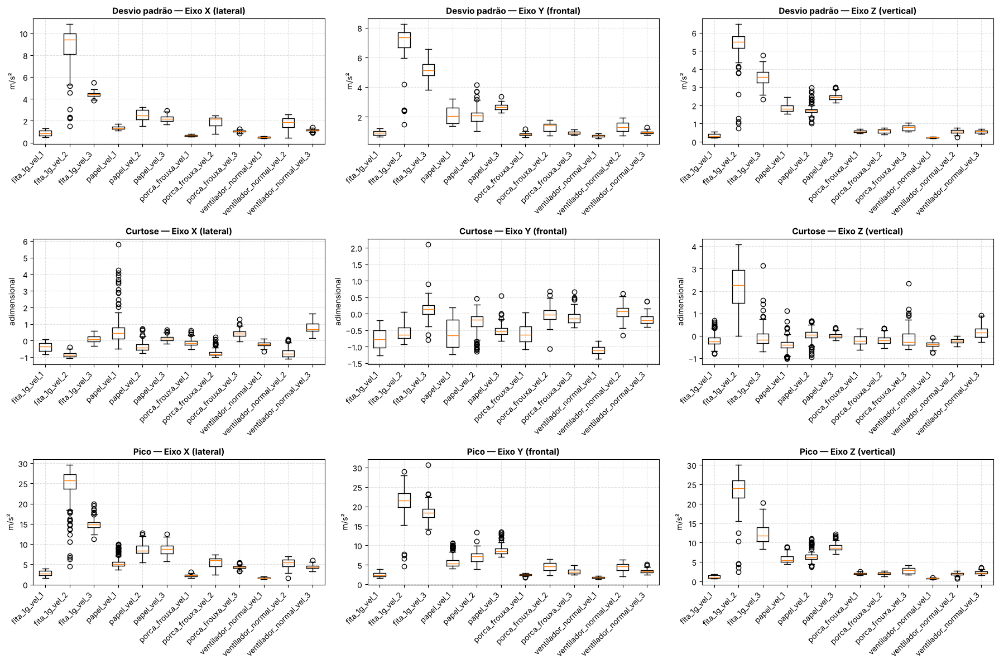

In [25]:
plotar_boxplots_features(features_tempo, list(bases.keys()))

### 7.2 — Dispersão 3D do desvio padrão por janela, em grupos

**O que buscamos:** ver, só com a intensidade da vibração nos três eixos, **o que já se separa**. Cada ponto é uma janela, posicionada pelo desvio padrão em X, Y e Z. **Cor = velocidade**, **símbolo = condição**.

Olhamos os mesmos pontos em seis recortes, do mais simples ao mais misturado:

1. **Apenas normal:** as três velocidades do ventilador saudável se separam?
2. **Cada anomalia separada** (um painel por falha): dentro de cada falha, as velocidades continuam se separando, ou a falha as embaralha?
3. **Todas as anomalias juntas:** as falhas se misturam entre si?
4. **Tudo junto:** normal e falhas no mesmo espaço.

**Como ler:** grupos de cores separados = as velocidades se distinguem; grupos de símbolos separados = as condições se distinguem. Cada painel tem a **sua própria escala**, para que grupos pequenos (como o normal) não fiquem espremidos.

**Duas versões:** a primeira figura usa a escala original (m/s²). Na segunda, os eixos estão em **escala logarítmica** (log10 do desvio padrão), que "abre" a região das vibrações pequenas, onde ficam o normal e a porca frouxa, e evita que a fita, muito mais forte, domine o espaço. É a mesma ideia do log usado nos Notebooks 03 e 04.

In [26]:
def plotar_dispersao_3d_std(features, catalogo):
    """Cada ponto é uma janela, nas coordenadas (std_x, std_y, std_z).

    Cor = velocidade. Símbolo = condição.
    """
    condicoes = sorted(catalogo["condicao"].unique())
    fig = plt.figure(figsize=(10, 8))
    ax = fig.add_subplot(111, projection="3d")
    for nome, grupo in features.groupby("base"):
        condicao = catalogo.loc[nome, "condicao"]
        velocidade = catalogo.loc[nome, "velocidade"]
        ax.scatter(
            grupo["std_x"], grupo["std_y"], grupo["std_z"],
            color=CORES_VELOCIDADE.get(velocidade, "gray"),
            marker=MARCADORES_CONDICAO[condicoes.index(condicao) % len(MARCADORES_CONDICAO)],
            alpha=0.6, s=28, label=nome,
        )
    ax.set_xlabel(f"std X ({UNIDADE})")
    ax.set_ylabel(f"std Y ({UNIDADE})")
    ax.set_zlabel(f"std Z ({UNIDADE})")
    ax.set_title(f"Desvio padrão por janela de {JANELA_S} s", fontsize=13, fontweight="bold")
    ax.legend(loc="upper left", fontsize=8)
    plt.tight_layout()
    plt.show()

def montar_grupos_3d(catalogo, condicao_normal=CONDICAO_NORMAL):
    """Lista de (título, condições) para os painéis: normal, cada anomalia, todas as anomalias e tudo junto."""
    anomalias = [c for c in sorted(catalogo["condicao"].unique()) if c != condicao_normal]
    grupos = [("Apenas normal", [condicao_normal])]
    grupos += [(f"Só {anomalia}", [anomalia]) for anomalia in anomalias]
    grupos += [("Todas as anomalias juntas", anomalias), ("Tudo junto", [condicao_normal] + anomalias)]
    return grupos


def plotar_dispersoes_3d_por_grupo(features, catalogo, grupos, em_log=False, colunas_fig=3):
    """Um gráfico 3D (std_x, std_y, std_z) por grupo de condições. Cor = velocidade, símbolo = condição."""
    condicoes = sorted(catalogo["condicao"].unique())
    transformar = np.log10 if em_log else (lambda valores: valores)
    sufixo = "log10 " if em_log else ""
    linhas = int(np.ceil(len(grupos) / colunas_fig))
    fig = plt.figure(figsize=(6.5 * colunas_fig, 5.8 * linhas))
    for k, (titulo, condicoes_do_grupo) in enumerate(grupos, start=1):
        ax = fig.add_subplot(linhas, colunas_fig, k, projection="3d")
        for nome, grupo in features[features["condicao"].isin(condicoes_do_grupo)].groupby("base"):
            condicao = catalogo.loc[nome, "condicao"]
            velocidade = catalogo.loc[nome, "velocidade"]
            ax.scatter(transformar(grupo["std_x"]), transformar(grupo["std_y"]), transformar(grupo["std_z"]),
                       color=CORES_VELOCIDADE.get(velocidade, "gray"),
                       marker=MARCADORES_CONDICAO[condicoes.index(condicao) % len(MARCADORES_CONDICAO)],
                       alpha=0.55, s=16, label=f"{condicao} V{velocidade}")
        ax.set_xlabel(f"{sufixo}std X", fontsize=8)
        ax.set_ylabel(f"{sufixo}std Y", fontsize=8)
        ax.set_zlabel(f"{sufixo}std Z", fontsize=8)
        ax.tick_params(labelsize=7)
        ax.set_title(titulo, fontsize=11, fontweight="bold")
        ax.legend(loc="upper left", fontsize=6, ncol=2 if len(condicoes_do_grupo) > 2 else 1)
    escala = "escala logarítmica (log10 do desvio padrão)" if em_log else f"escala original ({UNIDADE})"
    fig.suptitle(f"Desvio padrão por janela de {JANELA_S} s — {escala}", fontsize=13, fontweight="bold")
    plt.tight_layout(rect=[0, 0, 1, 0.97])
    plt.show()

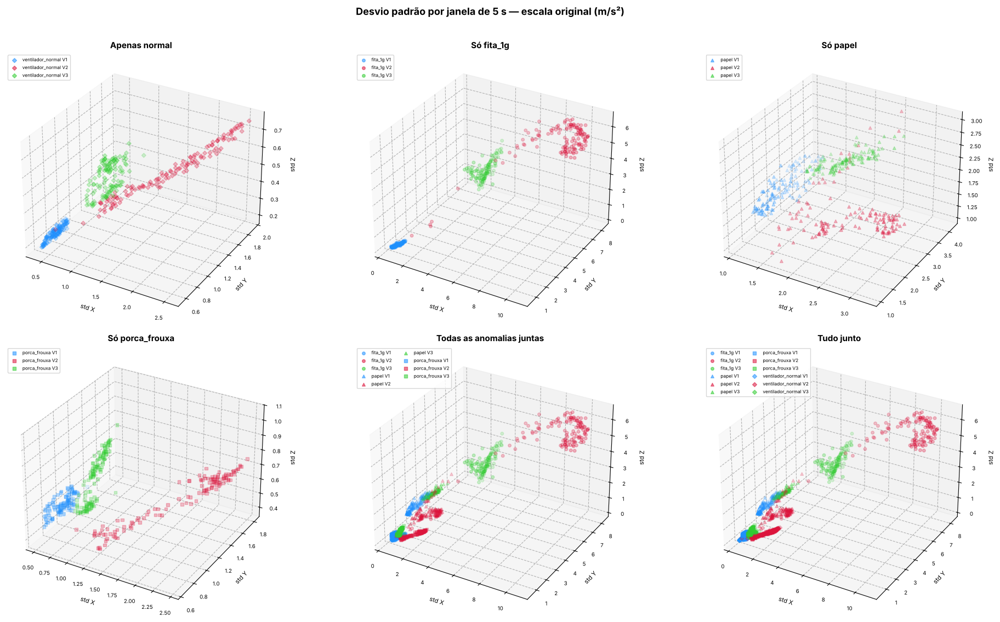

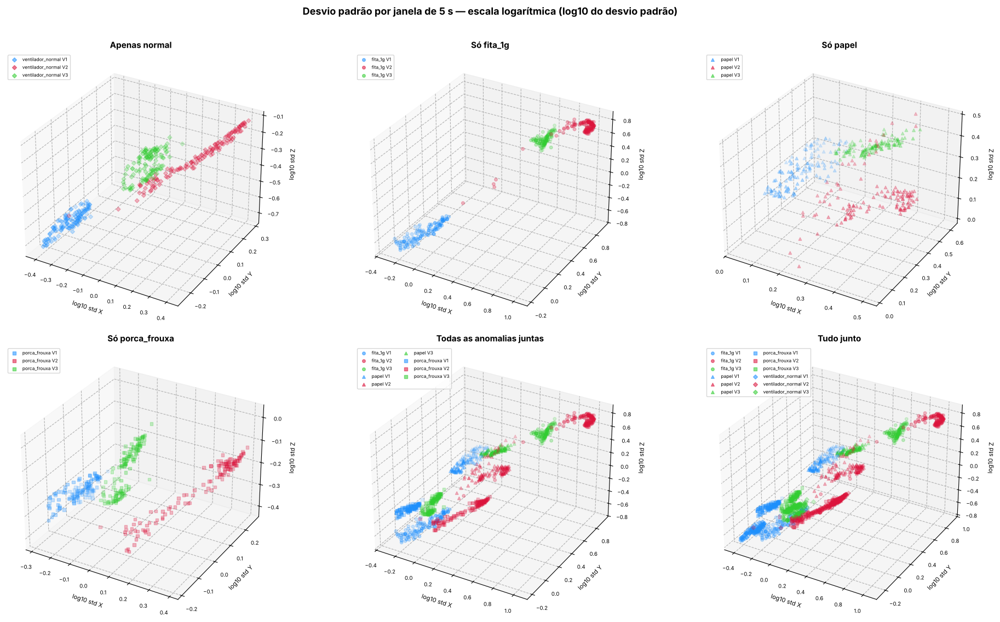

In [27]:
grupos_3d = montar_grupos_3d(catalogo)
plotar_dispersoes_3d_por_grupo(features_tempo, catalogo, grupos_3d, em_log=False)
plotar_dispersoes_3d_por_grupo(features_tempo, catalogo, grupos_3d, em_log=True)

### Conclusões do Passo 7 (nesta execução)

**Médias do desvio padrão no eixo X** (m/s²), por condição e velocidade:

| | Vel 1 | Vel 2 | Vel 3 |
| --- | --- | --- | --- |
| normal | 0,48 | 1,82 | 1,15 |
| porca frouxa | 0,66 | 1,94 | 1,05 |
| papel | 1,35 | 2,49 | 2,16 |
| fita 1g | 0,88 | 8,72 | 4,40 |

* **Fita:** muito acima do normal nas Vel 2 e 3 (4 a 5 vezes); na Vel 1, só ~1,8 vez.
* **Papel:** acima do normal nas três velocidades (1,4 a 2,8 vezes), e é a falha que mais se destaca **na Vel 1**.
* **Porca frouxa:** praticamente igual ao normal (0,9 a 1,4 vez). **Só com as features de tempo, a porca frouxa dificilmente se separa do normal**, principalmente nas Vel 2 e 3. Se ela for separável, a diferença deve estar no espectro (Passo 8 e Notebook 02).
**Dispersão 3D (7.2), painel por painel:**

* **Apenas normal:** as três velocidades formam grupos distintos, mas com formatos diferentes. **Vel 1 e Vel 3 são nuvens compactas.** A **Vel 2 é uma "linha" comprida**: é o **aquecimento** visto no Passo 6, com a intensidade subindo ao longo da gravação. **O começo da linha da Vel 2 (motor frio) encosta na nuvem da Vel 3**, então só com intensidade, um normal V2 frio pode parecer um normal V3.
* **Só fita:** as três velocidades se separam bem, com a Vel 2 muito acima. Os pontos soltos entre a Vel 1 e a Vel 2 são os primeiros ~30 s da fita V2, quando a vibração ainda estava subindo (Passo 6).
* **Só papel:** três grupos distintos. A Vel 2 é mais espalhada, pelo começo irregular da gravação.
* **Só porca frouxa:** Vel 1 e Vel 3 são nuvens próximas, mas separadas; a Vel 2 é de novo uma linha comprida (aquecimento).
* **Todas as anomalias juntas:** a fita (V2 e V3) fica isolada no alto. Papel e porca ficam mais embaixo, mas em regiões diferentes.
* **Tudo junto:** na escala logarítmica dá para ver o principal: **o normal e a porca frouxa ficam praticamente sobrepostos em cada velocidade** (as linhas vermelhas da Vel 2 se cruzam e as nuvens da Vel 1 e da Vel 3 se misturam). A fita e o papel se destacam.

**Conclusão do 7.2:** com só três números (o desvio padrão de cada eixo), **as velocidades se separam dentro de cada condição** e **fita e papel se separam do normal**. **A porca frouxa não se separa do normal só com intensidade.** E o **aquecimento da Vel 2** faz o normal ocupar uma faixa larga, que vai encostar nas outras condições e velocidades.

* **Curtose (depois do corte do Passo 4.2):** perto de zero na maioria das bases. A fita V2 tem curtose média de ~2 no eixo Z: são os impactos regulares da massa, que aparecem como picos fortes no sinal.

## Passo 8 — FFT com janela de Hanning

**O que buscamos:** descobrir **em quais frequências** a vibração acontece. A FFT decompõe o sinal em frequências, e a altura de cada pico mostra a força daquela frequência.

Ao recortar o sinal de forma abrupta, as bordas "cortam" as ondas ao meio e criam ruído falso na base dos picos (*vazamento espectral*). A **janela de Hanning** suaviza as bordas antes da FFT e deixa os picos mais finos e nítidos. O espectro final ignora frequências abaixo de `F_MIN_HZ` (deriva lenta do sensor) e acima de `F_MAX_HZ`.

* **8.1 — Efeito da janela de Hanning no tempo**, numa única base.
* **8.2 — FFT sem janela vs. com Hanning**, na mesma base.
* **8.3 — Espectro de todas as bases**, com a mesma escala vertical por velocidade, para comparar normal e anomalia.

In [28]:
def calcular_fft(sinal_1d, usar_hanning=True):
    """FFT de um eixo. Devolve (frequências em Hz, magnitude na mesma unidade do sinal).

    O sinal é centralizado em zero (remove a gravidade). A magnitude é compensada para que a altura
    do pico seja a amplitude da onda: fator 2/N sem janela e 4/N com Hanning, que perde metade da energia.
    """
    n = len(sinal_1d)
    centrado = sinal_1d - sinal_1d.mean()
    if usar_hanning:
        espectro = np.fft.rfft(centrado * np.hanning(n))
        fator = 4.0 / n
    else:
        espectro = np.fft.rfft(centrado)
        fator = 2.0 / n
    frequencias = np.fft.rfftfreq(n, d=1.0 / TAXA_AMOSTRAGEM_HZ)
    return frequencias, np.abs(espectro) * fator


def calcular_espectro_da_base(df, inicio_s=INICIO_FFT_S, janela_s=JANELA_S, usar_hanning=True):
    """FFT dos três eixos numa janela da base, só entre F_MIN_HZ e F_MAX_HZ.

    Devolve (frequências, {eixo: magnitude}).
    """
    tamanho = int(janela_s * TAXA_AMOSTRAGEM_HZ)
    inicio = int(inicio_s * TAXA_AMOSTRAGEM_HZ)
    trecho = df[EIXOS].iloc[inicio: inicio + tamanho]
    if len(trecho) < tamanho:
        raise ValueError(f"A base não tem {janela_s} s a partir do segundo {inicio_s}.")
    magnitudes = {}
    for eixo in EIXOS:
        frequencias, magnitudes[eixo] = calcular_fft(trecho[eixo].to_numpy(), usar_hanning)
    faixa = (frequencias > F_MIN_HZ) & (frequencias <= F_MAX_HZ)
    return frequencias[faixa], {eixo: magnitudes[eixo][faixa] for eixo in EIXOS}


def plotar_efeito_hanning(df, nome, eixo="x", inicio_s=INICIO_FFT_S, janela_s=JANELA_S):
    """Mostra, no tempo, o sinal centralizado antes e depois de multiplicar pela janela de Hanning."""
    tamanho = int(janela_s * TAXA_AMOSTRAGEM_HZ)
    inicio = int(inicio_s * TAXA_AMOSTRAGEM_HZ)
    sinal_1d = df[eixo].to_numpy()[inicio: inicio + tamanho]
    centrado = sinal_1d - sinal_1d.mean()
    janela = np.hanning(tamanho)
    tempo = np.arange(tamanho) / TAXA_AMOSTRAGEM_HZ

    plt.figure(figsize=(14, 4))
    plt.plot(tempo, centrado, color="lightgray", label="Sinal centralizado (bordas bruscas)")
    plt.plot(tempo, centrado * janela, color="red", alpha=0.9, label="Com janela de Hanning (bordas suaves)")
    plt.plot(tempo, janela * np.abs(centrado).max(), color="black", linestyle="--", label="Formato da janela")
    plt.title(f"Efeito da janela de Hanning — {nome}, {NOMES_EIXOS[eixo]}", fontsize=13, fontweight="bold")
    plt.xlabel("Tempo (s)")
    plt.ylabel(f"Aceleração ({UNIDADE})")
    plt.legend(loc="upper right")
    plt.tight_layout()
    plt.show()


def plotar_fft_sem_janela_vs_hanning(df, nome):
    """Grade 3x2: cada linha é um eixo; à esquerda a FFT sem janela, à direita com Hanning."""
    fig, axs = plt.subplots(len(EIXOS), 2, figsize=(18, 9), sharex=True, sharey="row")
    versoes = [(False, "FFT sem janela"), (True, "FFT com Hanning")]
    for coluna, (usar_hanning, titulo) in enumerate(versoes):
        frequencias, magnitudes = calcular_espectro_da_base(df, usar_hanning=usar_hanning)
        for linha, eixo in enumerate(EIXOS):
            ax = axs[linha, coluna]
            ax.plot(frequencias, magnitudes[eixo], color=CORES_EIXOS[eixo], linewidth=1.1)
            ax.fill_between(frequencias, magnitudes[eixo], color=CORES_EIXOS[eixo], alpha=0.2)
            if linha == 0:
                ax.set_title(titulo, fontsize=12, fontweight="bold")
            if coluna == 0:
                ax.set_ylabel(f"{NOMES_EIXOS[eixo]}\nMagnitude ({UNIDADE})")
    axs[-1, 0].set_xlabel("Frequência (Hz)")
    axs[-1, 1].set_xlabel("Frequência (Hz)")
    fig.suptitle(f"{nome} — janela de {JANELA_S} s a partir do segundo {INICIO_FFT_S}", fontsize=14, fontweight="bold")
    plt.tight_layout()
    plt.show()


def desenhar_marcas_de_frequencia(ax, nome, freq_1x_por_base, n_harmonicas, freqs_referencia_hz):
    """Desenha linhas verticais opcionais: 1X e harmônicas da base e frequências de referência."""
    freq_1x = freq_1x_por_base.get(nome)
    if freq_1x is not None:
        for k in range(1, n_harmonicas + 1):
            ax.axvline(k * freq_1x, color="orange", linestyle="--", alpha=0.8, label=f"{k}X ({k * freq_1x:.1f} Hz)")
    for freq in freqs_referencia_hz:
        ax.axvline(freq, color="black", linestyle=":", alpha=0.6, label=f"{freq} Hz")


def plotar_espectros_das_bases(bases, catalogo, freq_1x_por_base, n_harmonicas, freqs_referencia_hz):
    """Grade (condição x velocidade) com o espectro dos 3 eixos de cada base.

    A escala vertical é compartilhada por coluna (mesma velocidade), para comparar normal e anomalia.
    """
    fig, axs, celulas = criar_grade(
        catalogo, largura=7, altura=3.6, sharex=True, sharey="col",
        rotulo_x="Frequência (Hz)", rotulo_y=f"Magnitude ({UNIDADE})",
    )
    for ax, nome in celulas:
        frequencias, magnitudes = calcular_espectro_da_base(bases[nome])
        for eixo in EIXOS:
            ax.plot(frequencias, magnitudes[eixo], color=CORES_EIXOS[eixo], linewidth=1, alpha=0.85, label=NOMES_EIXOS[eixo])
        desenhar_marcas_de_frequencia(ax, nome, freq_1x_por_base, n_harmonicas, freqs_referencia_hz)
        ax.legend(loc="upper right", fontsize=7)
    fig.suptitle(f"Espectro com Hanning — janela de {JANELA_S} s a partir do segundo {INICIO_FFT_S}", fontsize=14, fontweight="bold")
    plt.tight_layout()
    plt.show()

def calcular_espectro_medio(df, janela_s=JANELA_S, usar_hanning=True):
    """Média dos espectros de todas as janelas da base (sem sobreposição), só entre F_MIN_HZ e F_MAX_HZ.

    Devolve (frequências, {eixo: magnitude média}). Ruído aleatório se cancela na média; picos que se repetem ficam.
    """
    tamanho = int(janela_s * TAXA_AMOSTRAGEM_HZ)
    n_janelas = len(df) // tamanho
    soma = None
    for k in range(n_janelas):
        frequencias, magnitudes = calcular_espectro_da_base(df, inicio_s=k * janela_s, janela_s=janela_s, usar_hanning=usar_hanning)
        soma = magnitudes if soma is None else {eixo: soma[eixo] + magnitudes[eixo] for eixo in EIXOS}
    return frequencias, {eixo: soma[eixo] / n_janelas for eixo in EIXOS}


def plotar_espectros_medios(bases, catalogo):
    """Grade (condição x velocidade) com o espectro médio de todas as janelas, mesma escala vertical por velocidade."""
    fig, axs, celulas = criar_grade(catalogo, largura=6.5, altura=3.2, sharex=True, sharey="col",
                                    rotulo_x="Frequência (Hz)", rotulo_y=f"Magnitude ({UNIDADE})")
    for ax, nome in celulas:
        frequencias, magnitudes = calcular_espectro_medio(bases[nome])
        for eixo in EIXOS:
            ax.plot(frequencias, magnitudes[eixo], color=CORES_EIXOS[eixo], linewidth=0.9, label=NOMES_EIXOS[eixo])
        ax.legend(loc="upper right", fontsize=7)
    fig.suptitle(f"Espectro médio de todas as janelas de {JANELA_S} s (Hanning)", fontsize=13, fontweight="bold")
    plt.tight_layout()
    plt.show()

### 8.1 — Efeito da janela de Hanning (uma base)

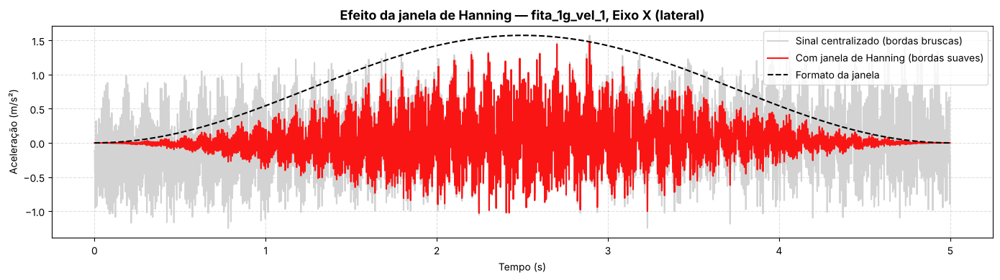

In [29]:
nome_exemplo = BASE_EXEMPLO if BASE_EXEMPLO is not None else list(bases.keys())[0]
plotar_efeito_hanning(bases[nome_exemplo], nome_exemplo)

### 8.2 — FFT sem janela vs. com Hanning (uma base)

Repare que, com Hanning, a base dos picos fica mais limpa.

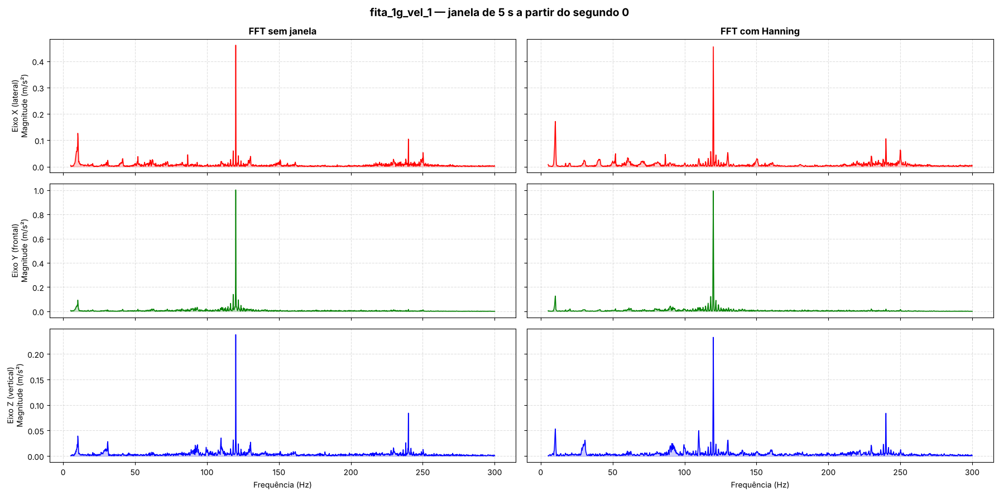

In [30]:
plotar_fft_sem_janela_vs_hanning(bases[nome_exemplo], nome_exemplo)

### 8.3 — Espectro de todas as bases

Por padrão, os gráficos saem **sem marcas**. Para marcar a frequência de rotação (**1X**) e suas harmônicas:

1. Rode a célula abaixo e **olhe os gráficos**: o 1X costuma ser o primeiro pico forte em baixas frequências, e as harmônicas são múltiplos dele (2X, 3X, ...).
2. Anote o valor em Hz de cada base.
3. Na célula, descomente o bloco `FREQ_1X_POR_BASE` (selecione as linhas e use `Ctrl + /`), troque pelos valores que você viu e rode de novo.
4. Para marcar frequências fixas (por exemplo, o ruído da rede elétrica), descomente a linha de `FREQS_REFERENCIA_HZ`.

Os valores do exemplo (11,2, 19,5 e 23,5 Hz) vêm dos dados antigos. **Nos dados novos, a rotação das Vel 1 e 2 sobe durante a gravação** (aquecimento, veja a conclusão do Passo 9), então um único valor de 1X por base vale só para o trecho analisado (`INICIO_FFT_S`).

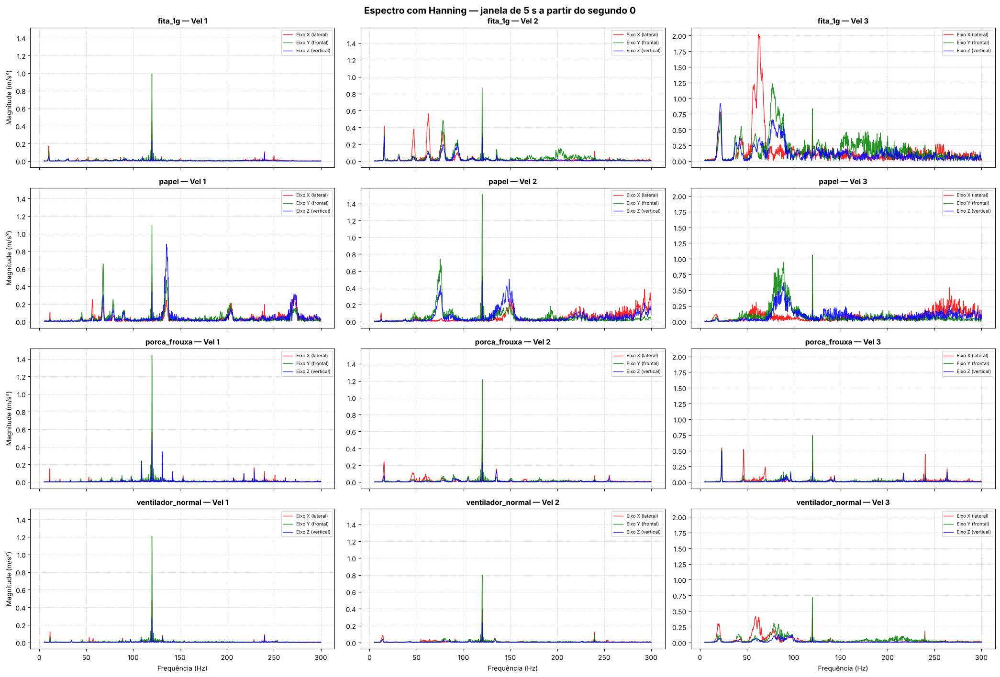

In [31]:
FREQ_1X_POR_BASE = {}        # sem marcas de 1X por padrão
N_HARMONICAS = 4             # quantos múltiplos desenhar (1X, 2X, 3X, 4X)
FREQS_REFERENCIA_HZ = []     # sem linhas de referência por padrão

# FREQ_1X_POR_BASE = {
#     "ventilador_normal_vel_1": 11.2,
#     "ventilador_normal_vel_2": 19.5,
#     "ventilador_normal_vel_3": 23.5,
#     "fita_1g_vel_1": 11.2,
#     "fita_1g_vel_2": 19.5,
#     "fita_1g_vel_3": 23.5,
# }
# FREQS_REFERENCIA_HZ = [120, 240]

plotar_espectros_das_bases(bases, catalogo, FREQ_1X_POR_BASE, N_HARMONICAS, FREQS_REFERENCIA_HZ)

### Conclusões do Passo 8 (nesta execução)

**Atenção:** o espectro desta figura usa **uma janela de 5 s no começo de cada base** (`INICIO_FFT_S = 0`, ou seja, de 5 a 10 s da gravação original, com o motor ainda frio). Ele mostra o começo, não a gravação inteira.

* **Uma linha forte em 120 Hz aparece em todas as bases**, principalmente no eixo Y, inclusive no normal. Como não depende da condição nem da velocidade, a hipótese é que seja de origem elétrica (o dobro da frequência da rede de 60 Hz, típico do zumbido magnético do motor) e não da hélice. **Vale confirmar com o orientador.** Ela entra nas features como a faixa de 115–125 Hz de todas as bases.
* **Normal:** espectro limpo, com picos pequenos em 1X e harmônicas (a Vel 3 tem uma região entre 50 e 100 Hz um pouco mais ativa).
* **Fita:** picos fortes nas harmônicas da rotação (Vel 2: 47, 63 e 78 Hz; Vel 3: forte entre 55 e 90 Hz, chegando a 2 m/s² no eixo X).
* **Papel:** energia espalhada em faixas largas, inclusive em frequências altas (Vel 1: 70, 135, 205 e 270 Hz; Vel 2 e 3: uma faixa larga em ~75–90 Hz e energia acima de 200 Hz). É o padrão esperado de um **impacto repetido**, que espalha energia por muitas frequências.
* **Porca frouxa:** parecida com o normal, com alguns picos estreitos a mais (por exemplo, perto de 110 e 130 Hz na Vel 1 e 240 Hz na Vel 3). São candidatos a "assinatura" da porca, a conferir no Notebook 02.

### 8.4 — Espectro médio da gravação inteira

**Por que este gráfico existe:** o espectro do 8.3 usa **uma única janela de 5 s** (a partir de `INICIO_FFT_S`). Uma janela só mostra o que acontecia **naqueles 5 s**, e nos dados novos o começo de cada gravação é um momento especial: motor frio, rotação ainda subindo, e em algumas bases (fita V2, papel V2) a vibração ainda se acomodando. Além disso, uma janela só carrega todo o ruído aleatório daquele trecho.

**O que fazemos aqui:** calculamos o espectro de **todas as janelas** da base e tiramos a **média**. O ruído aleatório, que muda de janela para janela, se cancela. O que se repete (rotação, harmônicas, a linha de 120 Hz, as ressonâncias) fica. É o "retrato médio" da gravação.

**Uma limitação:** nas Vel 1 e 2 a rotação sobe com o aquecimento, então os picos das harmônicas ficam um pouco **alargados** na média (cada janela tem o pico num lugar um pouco diferente). Na Vel 3, que é estável, os picos ficam finos.

**Como ler:** compare com o 8.3. Se um pico aparece nos dois, ele é típico da base. Se aparece só no 8.3, era coisa daquele trecho inicial.

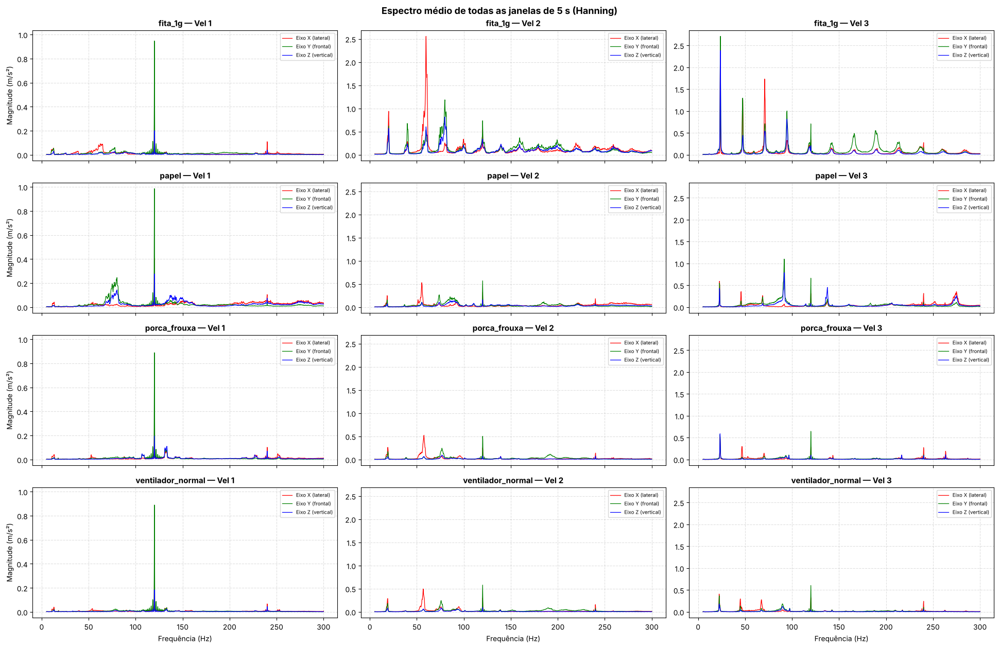

In [32]:
plotar_espectros_medios(bases, catalogo)

### Conclusões do Passo 8.4 (nesta execução)

**Com a média de todas as janelas, os espectros ficam limpos.** O aspecto "ruidoso" do 8.3 vinha de **olhar uma janela só, no começo da gravação** (motor frio, vibração ainda se acomodando), e não de os dados novos serem piores. Conferimos com os dados antigos, do mesmo jeito: a linha de 120 Hz (0,6 a 0,95 m/s² no eixo Y) e o ruído de fundo entre 150 e 300 Hz (0,003 a 0,018 m/s² no normal) têm **o mesmo tamanho nos dados antigos e nos novos**.

* **Vel 3 (rotação estável): as harmônicas aparecem como um "pente" de picos finos** em ~23, 46, 69 e 92 Hz (1X, 2X, 3X, 4X) no normal e na porca. Na fita, o mesmo pente fica de 2 a 6 vezes mais alto (o 1X chega a 2,7 m/s² no eixo Y).
* **Vel 1 e 2 (rotação subindo): os picos ficam mais largos**, porque a rotação muda durante a gravação e a média "espalha" cada harmônica.
* **A linha de 120 Hz continua em todas as bases, e aparece também uma linha menor em 240 Hz** (o dobro). Duas linhas fixas, em 120 e 240 Hz, que não acompanham a rotação, reforçam a hipótese de origem elétrica (zumbido magnético do motor, a 2 e 4 vezes os 60 Hz da rede).
* **Normal × porca frouxa:** na Vel 2 os dois espectros são quase idênticos. Nas Vel 1 e 3 a porca tem alguns picos estreitos a mais (Vel 1: perto de 107 e 130–135 Hz; Vel 3: perto de 215 e 262 Hz). São os candidatos a "assinatura" da porca.
* **Papel:** além das harmônicas, tem **faixas largas** (Vel 1: 75–80 Hz e 130–150 Hz; Vel 3: um pico forte perto de 92 Hz e energia em 270 Hz), o padrão de um impacto repetido.

**Para os próximos notebooks:** as features de FFT são calculadas janela por janela (sem média), então elas carregam o ruído de cada janela. Isso é esperado e vai aparecer como variação dentro de cada condição. O Notebook 02 mede quais faixas separam as condições **apesar** desse ruído.

## Passo 9 — Espectrograma

**O que buscamos:** ver como as frequências **evoluem no tempo**. A FFT do Passo 8 olha uma janela só. O espectrograma (STFT) divide a base em fatias de 2 s (com Hanning e 1 s de sobreposição) e mostra a magnitude de cada frequência em cada instante: eixo horizontal = tempo, eixo vertical = frequência, cor = magnitude.

Como ler:

* **Linhas horizontais constantes:** frequências fixas. Numa base estável, tanto a rotação quanto o ruído elétrico aparecem assim.
* **Linhas que sobem, descem ou dão saltos:** a velocidade mudou ou oscilou durante a base.
* **Faixas que aparecem só em parte do tempo:** perturbação no teste.

Todos os gráficos usam a **mesma escala de cor**, então cores mais fortes significam vibração maior em qualquer base. O eixo analisado é `EIXO_ESPECTROGRAMA`.

In [33]:
def calcular_espectrograma(serie, nperseg_s=2, noverlap_s=1):
    """Espectrograma de um eixo (fatias de nperseg_s com Hanning), entre F_MIN_HZ e F_MAX_HZ.

    Devolve (frequências, tempos, magnitude), com a magnitude na unidade do sinal.
    """
    frequencias, tempos, potencia = signal.spectrogram(
        serie - serie.mean(),
        fs=TAXA_AMOSTRAGEM_HZ,
        window="hann",
        nperseg=int(nperseg_s * TAXA_AMOSTRAGEM_HZ),
        noverlap=int(noverlap_s * TAXA_AMOSTRAGEM_HZ),
        scaling="spectrum",
    )
    magnitude = np.sqrt(potencia) * 2.0
    faixa = (frequencias > F_MIN_HZ) & (frequencias <= F_MAX_HZ)
    return frequencias[faixa], tempos, magnitude[faixa, :]

In [34]:
def plotar_espectrogramas(bases, catalogo, eixo=EIXO_ESPECTROGRAMA):
    """Grade (condição x velocidade) com o espectrograma de um eixo, na mesma escala de cor.

    Usa imshow (uma imagem por base), que gasta muito menos memória que pcolormesh.
    """
    resultados = {nome: calcular_espectrograma(df[eixo].to_numpy()) for nome, df in bases.items()}
    valor_maximo = np.percentile(np.concatenate([m.ravel() for _, _, m in resultados.values()]), 99.5)

    fig, axs, celulas = criar_grade(
        catalogo, largura=7, altura=3.6, sharex=False, sharey=True,
        rotulo_x="Tempo (s)", rotulo_y="Frequência (Hz)",
    )
    for ax, nome in celulas:
        frequencias, tempos, magnitude = resultados[nome]
        grafico = ax.imshow(
            magnitude, origin="lower", aspect="auto", cmap="inferno", vmin=0, vmax=valor_maximo,
            interpolation="bilinear",
            extent=[tempos[0], tempos[-1], frequencias[0], frequencias[-1]],
        )
        ax.grid(False)
    fig.suptitle(f"Espectrograma — {NOMES_EIXOS[eixo]}", fontsize=14, fontweight="bold")
    plt.tight_layout()
    fig.colorbar(grafico, ax=axs, shrink=0.8, label=f"Magnitude ({UNIDADE})")
    plt.show()

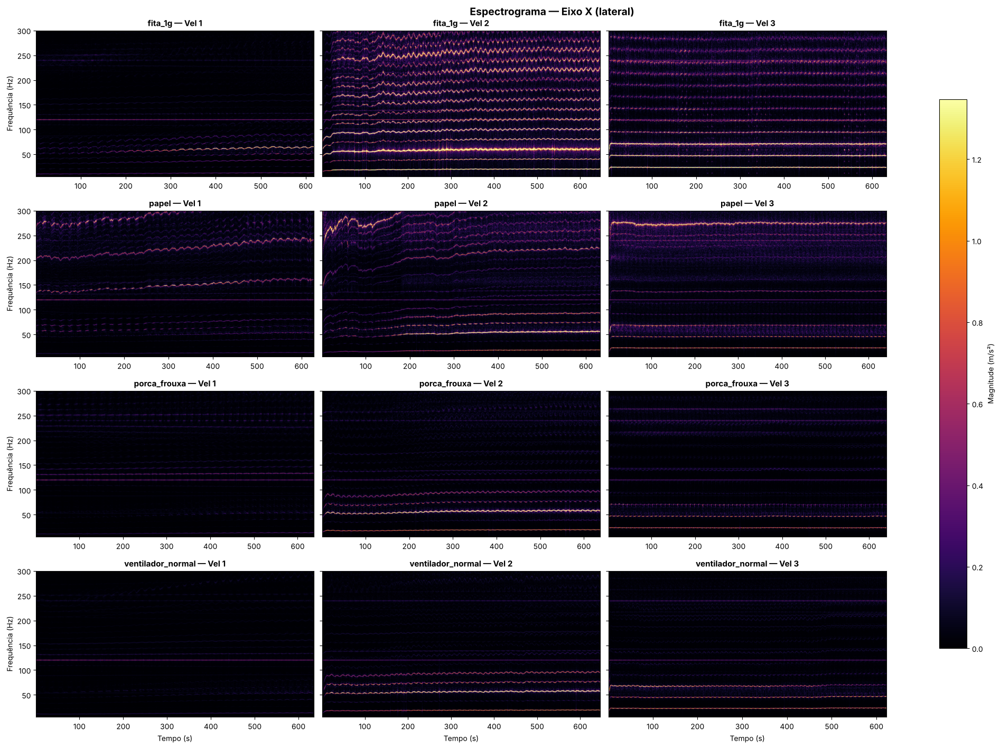

In [35]:
plotar_espectrogramas(bases, catalogo, eixo=EIXO_ESPECTROGRAMA)

### Conclusões do Passo 9 (nesta execução)

**O espectrograma confirma o aquecimento:**

* **Vel 1 e Vel 2: as linhas das harmônicas sobem ao longo da gravação** em todas as condições (normal, fita, papel, porca). É a **rotação aumentando enquanto o motor aquece**. Nas linhas mais altas, que são múltiplos da rotação, o aumento fica mais visível (no papel V1, a linha que começa em ~205 Hz termina em ~240 Hz).
* **Vel 3: as linhas ficam horizontais.** A rotação é estável desde o início.
* **A linha de 120 Hz fica perfeitamente horizontal** em todas as bases, não acompanha a rotação. Reforça a hipótese de origem elétrica (Passo 8).
* **As linhas "ondulam" levemente** (pequenas ondas em cima de cada harmônica, a cada ~10 s): é o **ciclo da oscilação** modulando a vibração.
* **fita V2:** as harmônicas aparecem fortes desde o começo, com o "pente" ficando mais intenso depois dos primeiros ~30 s, o mesmo trecho em que o desvio padrão subiu (Passo 6).
* **papel V2:** os primeiros ~150 s são bagunçados, com linhas que pulam. Depois se organizam, também como no Passo 6.
* **porca frouxa:** visualmente muito parecida com o normal da mesma velocidade.

## Resumo do Notebook 01 (dados novos)

| Pergunta | Resposta |
| --- | --- |
| Formato correto? | Sim: m/s², gravidade no Z, nenhum valor faltando. |
| Bases estáveis? | **Uma velocidade por base**, mas com **aquecimento**: nas Vel 1 e 2 a rotação sobe durante a gravação, e na Vel 2 a vibração cresce até 84% do começo para o fim, em todas as condições. A Vel 3 é estável. |
| Problemas encontrados | **Falhas de leitura do sensor nos primeiros 5 s** de quase todas as gravações (e no último segundo da porca V3). Resolvido descartando 5 s do começo e 5 s do fim de cada base. |
| Normal × falhas | **Fita:** muito forte nas Vel 2 e 3, fraca na Vel 1. **Papel:** visível nas três velocidades, com energia espalhada pelo espectro. **Porca frouxa:** quase igual ao normal no tempo, com alguns picos estreitos no espectro. |
| Frequências marcantes | Harmônicas da rotação (que sobem com o aquecimento nas Vel 1 e 2) e uma linha fixa de 120 Hz em todas as bases (provavelmente elétrica). |

**Para levar aos próximos notebooks:**
1. **O mesmo corte de 5 s no começo e no fim** precisa ser aplicado nos Notebooks 02 em diante.
2. **O normal muda dentro da gravação** (aquecimento). O controle do Notebook 02 vai mostrar quanto, e isso define o quão difícil será separar a porca frouxa.
3. **A porca frouxa é a falha a observar com mais cuidado**: se ela for separável, a diferença está no espectro, não na intensidade.

## O que conferir antes de seguir para o Notebook 02

* [ ] **Passo 4:** sem valores faltando, unidade correta e gravidade no eixo Z.
* [ ] **Passo 6:** nenhuma base com degrau no meio (se houver, corte de novo no Passo 2).
* [ ] **Passos 5 e 7:** a diferença entre normal e anomalia aparece em pelo menos uma feature ou eixo, ou, se não aparecer, anote isso.
* [ ] **Passos 8 e 9:** as frequências marcantes de cada velocidade estão anotadas (1X, harmônicas e eventuais frequências fixas).

**Próximo passo:** Notebook 02, a **análise comparativa** entre normal e anomalia, com as mesmas bases carregadas daqui.